# Project Deliverable 1: Data Collection, Cleaning, and Exploration

Name: Sandip Sitaula

Course: MSCS 634 – Advanced Big Data and Data Mining

Deliverable 1: Data Collection, Cleaning, and Exploration

## Step 1: Choosing the Dataset

I chose the Online Retail dataset from the UCI Machine Learning Repository.

Link: https://archive.ics.uci.edu/dataset/352/online+retail

I downloaded it on October 27, 2026 and saved it in the data folder.

The data is from a UK online store that sells gifts and home decor. Many of its customers are small shops that buy in bulk. Each row is one product on one invoice. The dates go from December 1, 2010 to December 9, 2011.

The 8 columns are:
- InvoiceNo: invoice number (starts with "C" if the order was cancelled)
- StockCode: product code
- Description: product name
- Quantity: number of units bought
- InvoiceDate: date and time of the invoice
- UnitPrice: price of one unit in pounds
- CustomerID: customer number
- Country: country of the customer

### Why I chose this dataset

I chose this dataset because it meets the project requirements and is a good fit for all four deliverables. It has 541,909 rows, which is much more than the 500 rows needed. It has 8 columns, and I can also create new columns from them, such as the line total, month, day of the week, hour, and customer features like recency and frequency. This gives me more than 10 features to work with.

Another reason is that this is real data with real problems. It has missing values, duplicate rows, cancelled orders, and some wrong values, so there is real cleaning work to do in this deliverable instead of using a dataset that is already clean.

Most importantly, I can use this dataset for every part of the project. For regression, I can predict how much a customer will spend. For classification, I can predict whether a customer is high-value or will buy again. For clustering, I can group customers by how they shop. Finally, every invoice is a shopping basket, so I can use association rules to find products that are often bought together.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Show numbers with 2 decimals
pd.set_option("display.float_format", "{:,.2f}".format)

## Step 2: Loading and Inspecting the Data

In [5]:
# Load data (codes as text)
raw = pd.read_excel("data/online_retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})

print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


The data has 541,909 rows and 8 columns. The first 5 rows all belong to one invoice (536365), so one invoice is spread over many rows, one row per product.

In [6]:
# Column info
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 33.1+ MB


Description and CustomerID have fewer values than the other columns, so they have missing values. CustomerID is stored as a decimal number (like 17850.0) even though it is just an ID.

In [7]:
# Basic statistics
raw.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


Some values do not make sense for sales:
- Quantity goes from -80,995 to 80,995. Negative numbers are cancellations or stock changes.
- UnitPrice has a negative minimum (-£11,062) and a very high maximum (£38,970).
- The mean quantity (9.6) is much higher than the median (3). This means a few very large orders pull the mean up.

In [8]:
# Unique values and dates
print(raw.nunique())
print()
print("First date:", raw["InvoiceDate"].min())
print("Last date:", raw["InvoiceDate"].max())

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

First date: 2010-12-01 08:26:00
Last date: 2011-12-09 12:50:00


There are 25,900 invoices, 4,070 products, 4,372 customers and 38 countries. There are more product names (4,223) than product codes (4,070), so some products have more than one name. I fix this later.

             missing  percent
InvoiceNo          0     0.00
StockCode          0     0.00
Description     1454     0.27
Quantity           0     0.00
InvoiceDate        0     0.00
UnitPrice          0     0.00
CustomerID    135080    24.93
Country            0     0.00


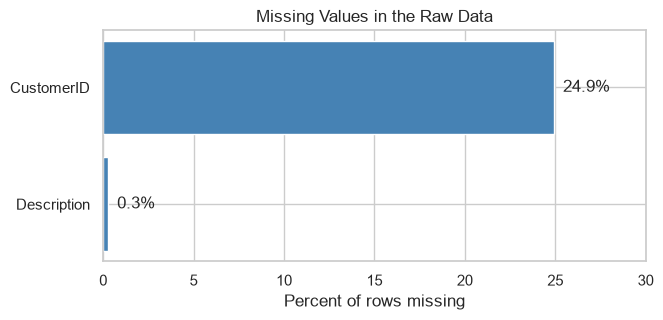

In [10]:
# Missing values
missing_count = raw.isna().sum()
missing_percent = raw.isna().mean() * 100
print(pd.DataFrame({"missing": missing_count, "percent": missing_percent.round(2)}))

missing_percent = missing_percent[missing_percent > 0]
plt.figure(figsize=(7, 3))
plt.barh(missing_percent.index, missing_percent.values, color="steelblue")
for i, value in enumerate(missing_percent.values):
    plt.text(value + 0.5, i, f"{value:.1f}%", va="center")
plt.title("Missing Values in the Raw Data")
plt.xlabel("Percent of rows missing")
plt.xlim(0, 30)
plt.show()

Only two columns have missing values:
- CustomerID: 135,080 rows (24.9%). This is a lot, so I need to look at it carefully.
- Description: 1,454 rows (0.3%).

## Step 3: Data Cleaning

For each problem, I first look at the rows, then decide what to do and explain why.

In [11]:
# Copy data, track rows
df = raw.copy()
steps = [("Raw data", len(df))]

### 3.1 Fix text

In [12]:
# Step 3.1: Fix text
descriptions = df["Description"].dropna()
print("Descriptions with extra spaces:", (descriptions != descriptions.str.strip()).sum())

df["Description"] = df["Description"].str.strip()

df["StockCode"] = df["StockCode"].str.upper()

Descriptions with extra spaces: 113453


113,453 descriptions had extra spaces. Without this fix, "WHITE METAL LANTERN" and "WHITE METAL LANTERN " would be counted as two different products.

### 3.2 Remove duplicates

In [13]:
# Step 3.2: Remove duplicates
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
steps.append(("Removed duplicates", len(df)))

Duplicate rows: 5268


### 3.3 Handle missing values

In [14]:
# Step 3.3a: Missing description
no_desc = df[df["Description"].isna()]
print("Rows with no description:", len(no_desc))
print("How many have price = 0:", (no_desc["UnitPrice"] == 0).sum())
print("How many have a CustomerID:", no_desc["CustomerID"].notna().sum())

Rows with no description: 1455
How many have price = 0: 1455
How many have a CustomerID: 0


All of these rows have price 0 and no customer. They are not real sales, so I remove them.

In [15]:
# Remove them
df = df.dropna(subset=["Description"])
steps.append(("Removed rows with no description", len(df)))

In [16]:
# Step 3.3b: Missing CustomerID
df["HasCustomerID"] = df["CustomerID"].notna()

print("Rows without CustomerID:", (~df["HasCustomerID"]).sum())
print()
print("Number of invoices:")
print(df.groupby("HasCustomerID")["InvoiceNo"].nunique())
print()
print("Median unit price:")
print(df.groupby("HasCustomerID")["UnitPrice"].median())
print()
print("Percent of rows from the UK:")
print(df.groupby("HasCustomerID")["Country"].apply(lambda c: (c == "United Kingdom").mean() * 100))

Rows without CustomerID: 133582

Number of invoices:
HasCustomerID
False     2255
True     22190
Name: InvoiceNo, dtype: int64

Median unit price:
HasCustomerID
False   3.29
True    1.95
Name: UnitPrice, dtype: float64

Percent of rows from the UK:
HasCustomerID
False   98.90
True    88.83
Name: Country, dtype: float64


The rows without a CustomerID are different from the others:
- Almost all of them (98.9%) are from the UK.
- They have higher prices (median £3.29 vs. £1.95).
- They come from only 2,255 invoices.

I think these are orders from guest shoppers who did not log in, and who pay normal retail prices instead of wholesale prices.

My decision: I keep these rows and use the HasCustomerID column to tell them apart.
- I cannot fill in (impute) a CustomerID, because that would create fake customers.
- If I removed them, I would lose 25% of real sales, which I need for product and basket analysis.
- When I look at customers (Step 4.7), I only use the rows that have a CustomerID.

### 3.4 Separate cancellations

In [17]:
# Step 3.4: Cancellations (C) and adjustments (A)
is_cancel = df["InvoiceNo"].str.startswith("C")
is_adjust = df["InvoiceNo"].str.startswith("A")
print("Cancellation rows:", is_cancel.sum())
print("Adjustment rows:", is_adjust.sum())

cancellations = df[is_cancel].copy()
df = df[~is_cancel & ~is_adjust]
steps.append(("Moved cancellations out", len(df)))

Cancellation rows: 9251
Adjustment rows: 3


Cancelled orders are not sales, so I moved them into their own table. I keep that table because how often a customer cancels could be a useful feature later. I also removed the 3 "Adjust bad debt" rows, because they are accounting entries.

### 3.5 Remove codes that are not products

In [18]:
# Step 3.5: Non-product codes
odd_codes = df[~df["StockCode"].str.match(r"^\d{5}[A-Z]*$")]
odd_codes.groupby("StockCode")["Description"].agg(["first", "count"]).sort_values("count", ascending=False).head(20)

,first,count
StockCode,,
POST,POSTAGE,1126
DOT,DOTCOM POSTAGE,708
M,Manual,323
C2,CARRIAGE,141
DCGSSGIRL,GIRLS PARTY BAG,13
BANK CHARGES,Bank Charges,12
DCGSSBOY,BOYS PARTY BAG,11
GIFT_0001_20,Dotcomgiftshop Gift Voucher £20.00,10
GIFT_0001_10,Dotcomgiftshop Gift Voucher £10.00,8


In [19]:
# Remove non-products
not_products = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B"]
remove = df["StockCode"].isin(not_products) | df["StockCode"].str.startswith("GIFT_")
print("Rows removed:", remove.sum())

df = df[~remove]
steps.append(("Removed postage, fees, vouchers", len(df)))

Rows removed: 2346


### 3.6 Remove zero or negative quantity and price

In [20]:
# Step 3.6: Zero or negative values
bad = df[(df["Quantity"] <= 0) | (df["UnitPrice"] <= 0)]
print("Rows with quantity <= 0 or price <= 0:", len(bad))
print()
print("Most common descriptions in these rows:")
print(bad["Description"].value_counts().head(10))

Rows with quantity <= 0 or price <= 0: 1046

Most common descriptions in these rows:
Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Name: count, dtype: int64


Most of these rows are notes from staff, like "check", "damaged", "found" or "thrown away". They are stock changes, not sales, so I remove them.

In [21]:
# Remove them
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
steps.append(("Removed zero/negative quantity or price", len(df)))

### 3.7 One name per product

In [22]:
# Step 3.7: Products with many names
names_per_code = df.groupby("StockCode")["Description"].nunique()
print("Stock codes with more than one name:", (names_per_code > 1).sum())

print()
print(df[df["StockCode"] == "16156L"]["Description"].value_counts())

Stock codes with more than one name: 212

Description
WRAP CAROUSEL     14
WRAP, CAROUSEL     4
Name: count, dtype: int64


In [23]:
# Use most common name
most_common_name = df.groupby("StockCode")["Description"].agg(lambda names: names.mode()[0])
df["Description"] = df["StockCode"].map(most_common_name)

names_per_code = df.groupby("StockCode")["Description"].nunique()
print("Stock codes with more than one name now:", (names_per_code > 1).sum())

print("New duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
steps.append(("Removed duplicates after fixing names", len(df)))

Stock codes with more than one name now: 0
New duplicate rows: 2


212 products had more than one name, usually a small difference like a comma ("WRAP CAROUSEL" vs. "WRAP, CAROUSEL"). Now each product has one name. This is important for association rules, because otherwise one product would look like two. After the fix, 2 rows became exact duplicates, so I removed them as well.

### 3.8 Noisy data and outliers

First I add some new columns. LineTotal (quantity × price) is the money for each row.

In [24]:
# New columns
df["LineTotal"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.to_period("M")
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

In [25]:
# Step 3.8: IQR outliers
def iqr_limits(values):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["Quantity", "UnitPrice", "LineTotal"]:
    low, high = iqr_limits(df[col])
    normal_pct = ((df[col] < low) | (df[col] > high)).mean() * 100

    log_values = np.log10(df[col])
    log_low, log_high = iqr_limits(log_values)
    log_pct = ((log_values < log_low) | (log_values > log_high)).mean() * 100

    print(f"{col}: normal IQR = {normal_pct:.2f}% outliers, log IQR = {log_pct:.2f}% outliers, "
          f"log upper limit = {10 ** log_high:,.0f}")

Quantity: normal IQR = 5.13% outliers, log IQR = 0.08% outliers, log upper limit = 499
UnitPrice: normal IQR = 6.84% outliers, log IQR = 0.93% outliers, log upper limit = 25
LineTotal: normal IQR = 7.87% outliers, log IQR = 1.52% outliers, log upper limit = 171


The normal IQR rule marks 5–8% of rows as outliers. I think this is too many. This store sells to wholesalers, so an order of 100 units is normal, not a mistake.

Because the data is very skewed, I also used the IQR rule on the log of the values. This marks far fewer rows (only 0.08% for quantity). With this rule, orders above about 499 units are unusual.

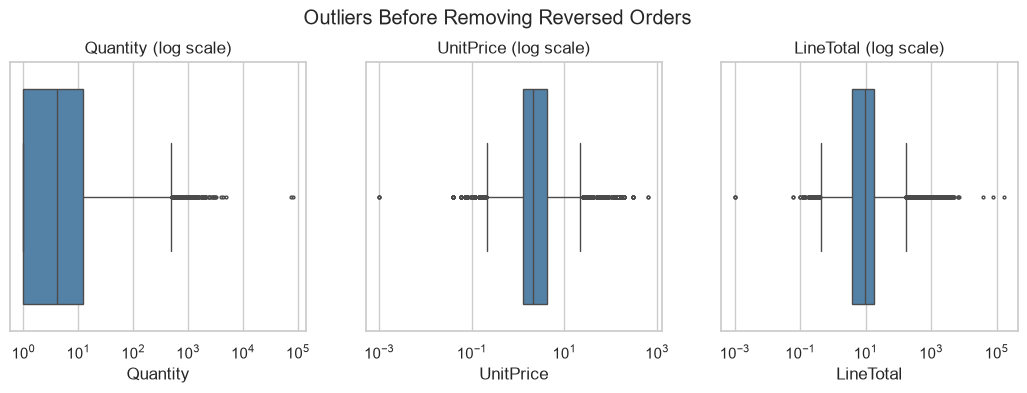

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,CustomerID
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00"
61619,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"12,346.00"
421632,573008,2011-10-27 12:26:00,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,"12,901.00"
206121,554868,2011-05-27 10:52:00,POPCORN HOLDER,4300,0.72,"13,135.00"
97432,544612,2011-02-22 10:43:00,EMPIRE DESIGN ROSETTE,3906,0.82,"18,087.00"
270885,560599,2011-07-19 17:04:00,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,"14,609.00"


In [26]:
# Box plots (log scale)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "LineTotal"]):
    sns.boxplot(x=df[col], ax=ax, color="steelblue", log_scale=True, fliersize=2)
    ax.set_title(f"{col} (log scale)")
plt.suptitle("Outliers Before Removing Reversed Orders", y=1.03)
plt.show()

df.sort_values("Quantity", ascending=False).head(6)[
    ["InvoiceNo", "InvoiceDate", "Description", "Quantity", "UnitPrice", "CustomerID"]]

The box plots show a few points very far to the right. The two biggest orders (80,995 and 74,215 units) are about 17 times bigger than the next one (4,800 units). When I checked the raw data, both were cancelled a few minutes later (invoices C581484 and C541433). So they look like typing mistakes.

I want to find all orders like this: big orders that were fully cancelled later.

In [27]:
# Big orders cancelled later
quantity_limit = 10 ** iqr_limits(np.log10(df["Quantity"]))[1]
big_orders = df[(df["Quantity"] > quantity_limit) & df["HasCustomerID"]]

last_cancel = {}
for index, row in cancellations.iterrows():
    key = (row["CustomerID"], row["StockCode"], -row["Quantity"])
    last_cancel[key] = max(last_cancel.get(key, row["InvoiceDate"]), row["InvoiceDate"])

reversed_rows = []
for index, row in big_orders.iterrows():
    key = (row["CustomerID"], row["StockCode"], row["Quantity"])
    if key in last_cancel and last_cancel[key] >= row["InvoiceDate"]:
        reversed_rows.append(index)

print(f"Quantity limit: {quantity_limit:,.0f} units")
print("Big orders that were cancelled later:", len(reversed_rows))
df.loc[reversed_rows].sort_values("Quantity", ascending=False).head(5)[
    ["InvoiceNo", "Description", "Quantity", "LineTotal", "CustomerID"]]

Quantity limit: 499 units
Big orders that were cancelled later: 21


,InvoiceNo,Description,Quantity,LineTotal,CustomerID
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60","16,446.00"
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,"77,183.60","12,346.00"
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,"6,539.40","15,749.00"
52710,540815,GIN + TONIC DIET METAL SIGN,2000,"3,700.00","15,749.00"
52709,540815,WHITE HANGING HEART T-LIGHT HOLDER,1930,"4,921.50","15,749.00"


I found 21 big orders that were cancelled later by the same customer, for the same product and the same quantity.

In [28]:
# Largest lines
df.sort_values("LineTotal", ascending=False).head(3)[
    ["InvoiceNo", "InvoiceDate", "Description", "Quantity", "UnitPrice", "LineTotal", "CustomerID"]]

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,LineTotal,CustomerID
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60","16,446.00"
61619,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60","12,346.00"
222680,556444,2011-06-10 15:28:00,PICNIC BASKET WICKER SMALL,60,649.50,"38,970.00","15,098.00"


The top line is £38,970: 60 picnic baskets at £649.50 each. The normal price of this product is around £5. I looked at all rows for this customer:

In [29]:
# Check this customer
raw[(raw["CustomerID"] == 15098)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222670,556442,22502,PICNIC BASKET WICKER SMALL,60,2011-06-10 15:22:00,4.95,"15,098.00",United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,"15,098.00",United Kingdom
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,"38,970.00","15,098.00",United Kingdom
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.50,"15,098.00",United Kingdom
222692,C556448,22502,PICNIC BASKET WICKER SMALL,-60,2011-06-10 15:39:00,4.95,"15,098.00",United Kingdom


The customer ordered 60 sets by mistake (invoice 556444). Three minutes later the store gave a "Manual" credit of exactly £38,970 (C556445). Then the customer ordered 1 set (556446). This order was undone with a manual credit, not a normal cancellation, so my matching did not find it. I add it by hand.

My decision: I remove these 22 reversed orders and their matching cancellations. They are worth £321,517, about 3% of all sales. If I kept them, total sales and the spending of a few customers would be too high.

I do not remove big orders that were not cancelled (like 4,800 gliders at £0.21), because they are real wholesale orders.

In [30]:
# Add manual-credit order
reversed_rows += list(df[df["InvoiceNo"] == "556444"].index)
print("Rows to remove:", len(reversed_rows))
print(f"Money in these rows: £{df.loc[reversed_rows, 'LineTotal'].sum():,.0f}")

reversed_keys = set(zip(df.loc[reversed_rows, "CustomerID"], df.loc[reversed_rows, "StockCode"],
                        df.loc[reversed_rows, "Quantity"]))
cancel_matches = [key in reversed_keys for key in zip(cancellations["CustomerID"], cancellations["StockCode"],
                                                      -cancellations["Quantity"])]
cancellations = cancellations[~np.array(cancel_matches)]

df = df.drop(index=reversed_rows)
steps.append(("Removed big orders that were reversed", len(df)))

cancellations = cancellations[~cancellations["StockCode"].isin(not_products)
                              & ~cancellations["StockCode"].str.startswith("GIFT_")]

Rows to remove: 22
Money in these rows: £321,517


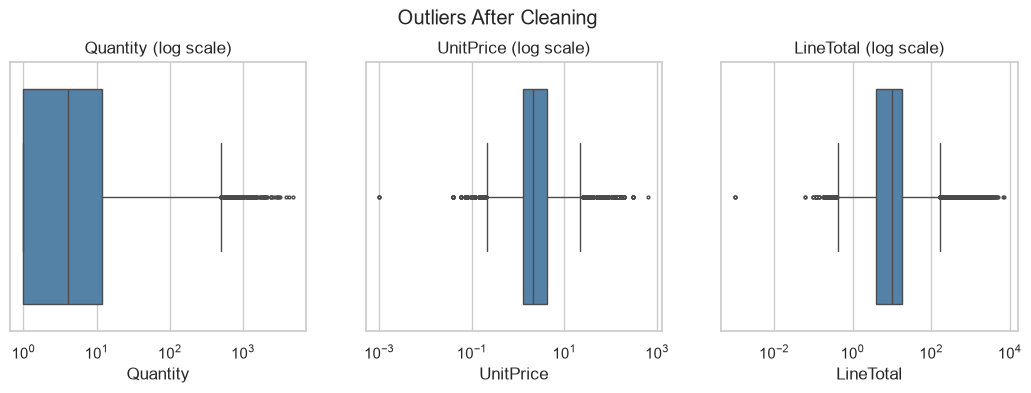

,InvoiceNo,Description,Quantity,UnitPrice,LineTotal,CustomerID
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72","17,450.00"
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40","15,749.00"
421601,573003,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00","14,646.00"
467804,576365,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,"4,781.60",NaN
160542,550461,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.40,"4,632.00","15,749.00"


In [31]:
# Box plots after cleaning
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "LineTotal"]):
    sns.boxplot(x=df[col], ax=ax, color="steelblue", log_scale=True, fliersize=2)
    ax.set_title(f"{col} (log scale)")
plt.suptitle("Outliers After Cleaning", y=1.03)
plt.show()

df.sort_values("LineTotal", ascending=False).head(5)[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "LineTotal", "CustomerID"]]

After cleaning, the biggest line is £7,145 and the biggest quantity is 4,800 units. Both are real bulk orders. There are still some extreme values, but they are real, so I keep them. For the models, I will use a log transform or scaling instead of removing more rows.

### 3.9 Cleaning summary

                                   Step  Rows left  Rows removed
                               Raw data     541909             0
                     Removed duplicates     536641          5268
       Removed rows with no description     535186          1455
                Moved cancellations out     525932          9254
        Removed postage, fees, vouchers     523586          2346
Removed zero/negative quantity or price     522540          1046
  Removed duplicates after fixing names     522538             2
  Removed big orders that were reversed     522516            22

Kept 96.4% of the rows


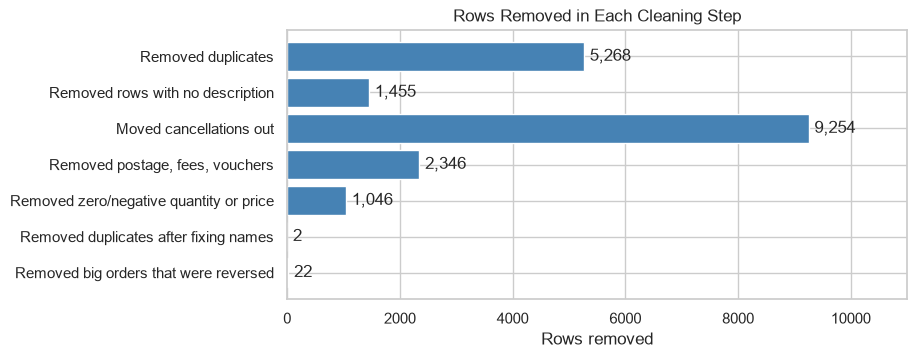

In [32]:
# Cleaning summary
summary = pd.DataFrame(steps, columns=["Step", "Rows left"])
summary["Rows removed"] = summary["Rows left"].shift(1) - summary["Rows left"]
summary["Rows removed"] = summary["Rows removed"].fillna(0).astype(int)
print(summary.to_string(index=False))
print()
print(f"Kept {len(df) / len(raw) * 100:.1f}% of the rows")

removed = summary.iloc[1:]
plt.figure(figsize=(8, 3.5))
plt.barh(removed["Step"], removed["Rows removed"], color="steelblue")
for i, value in enumerate(removed["Rows removed"]):
    plt.text(value + 100, i, f"{value:,}", va="center")
plt.gca().invert_yaxis()
plt.title("Rows Removed in Each Cleaning Step")
plt.xlabel("Rows removed")
plt.xlim(0, 11000)
plt.show()

I kept 96.4% of the rows. The biggest steps were moving out the cancellations and removing duplicates.

In [33]:
# Final check
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df.isna().sum())
df.describe()

Rows and columns: (522516, 13)
Duplicate rows: 0
Missing values:
InvoiceNo             0
StockCode             0
Description           0
Quantity              0
InvoiceDate           0
UnitPrice             0
CustomerID       131387
Country               0
HasCustomerID         0
LineTotal             0
Month                 0
DayOfWeek             0
Hour                  0
dtype: int64


,Quantity,InvoiceDate,UnitPrice,CustomerID,LineTotal,Hour
count,"522,516.00",522516,"522,516.00","391,129.00","522,516.00","522,516.00"
mean,10.31,2011-07-04 16:44:22.621087,3.27,"15,295.15",18.99,13.08
min,1.00,2010-12-01 08:26:00,0.00,"12,347.00",0.00,6.00
25%,1.00,2011-03-28 12:13:00,1.25,"13,969.00",3.90,11.00
50%,4.00,2011-07-20 11:55:00,2.08,"15,158.00",9.90,13.00
75%,12.00,2011-10-19 11:49:00,4.13,"16,794.00",17.70,15.00
max,"4,800.00",2011-12-09 12:50:00,649.50,"18,287.00","7,144.72",20.00
std,37.09,NaN,4.30,"1,710.35",63.36,2.44


Final check:
- No duplicate rows.
- Every quantity and price is above 0. The minimum price shows 0.00 only because of rounding (a few items cost £0.001).
- The only missing values are the CustomerIDs that I chose to keep.

## Step 4: Exploratory Data Analysis (EDA)

### 4.1 Distributions

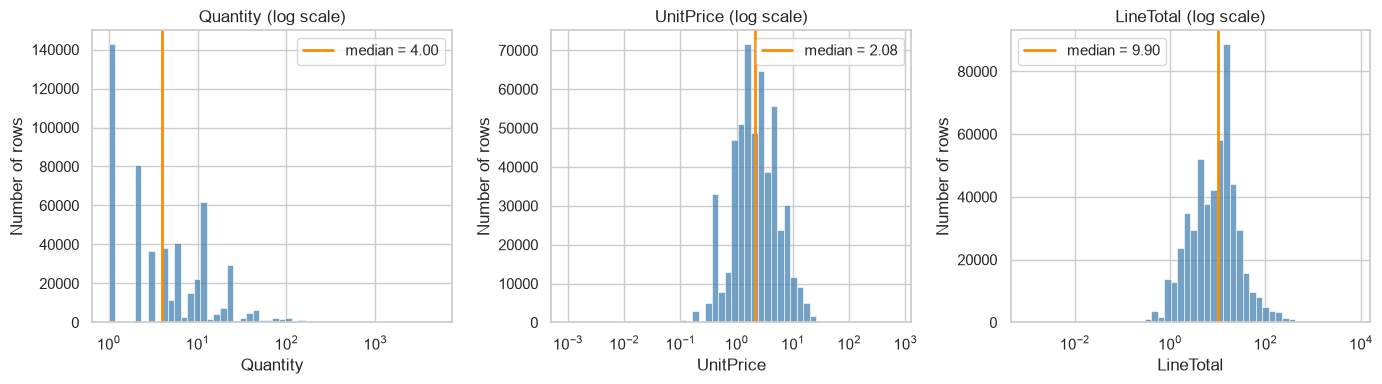

Skewness (0 = symmetric):
Quantity    33.30
UnitPrice   20.90
LineTotal   29.90
dtype: float64

Most common quantities:
Quantity
1     142661
2      80787
12     60823
6      40570
4      38237
3      36694
24     23943
10     22208
Name: count, dtype: int64


In [34]:
# Histograms
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Quantity", "UnitPrice", "LineTotal"]):
    sns.histplot(df[col], bins=50, log_scale=True, ax=ax, color="steelblue")
    ax.axvline(df[col].median(), color="darkorange", linewidth=2, label=f"median = {df[col].median():.2f}")
    ax.set_title(f"{col} (log scale)")
    ax.set_ylabel("Number of rows")
    ax.legend()
plt.tight_layout()
plt.show()

print("Skewness (0 = symmetric):")
print(df[["Quantity", "UnitPrice", "LineTotal"]].skew().round(1))
print()
print("Most common quantities:")
print(df["Quantity"].value_counts().head(8))

- All three columns are very right-skewed (skewness 33 for quantity, 21 for price). On a log scale, price and line total look close to a bell shape. So a log transform should help the models later.
- Quantity has peaks at 1, 2, 6, 12 and 24. Products are sold in packs of 6, 12 and 24, which makes sense for a wholesale store.
- A typical row is 4 units at £2.08, about £10 in total.

### 4.2 Sales over time

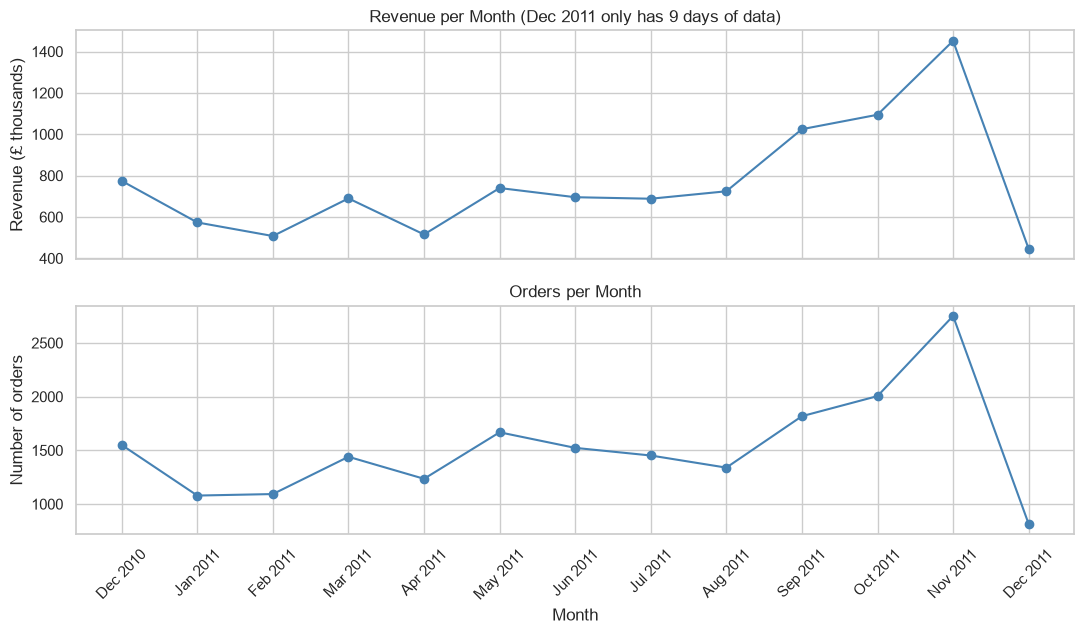

,revenue,orders
Month,,
2010-12,"774,363.36",1550
2011-01,"573,513.24",1079
2011-02,"507,799.87",1093
2011-03,"689,833.51",1440
2011-04,"515,377.99",1235
2011-05,"739,938.15",1668
2011-06,"695,524.43",1523
2011-07,"688,219.34",1452
2011-08,"724,216.50",1339


In [35]:
# Monthly sales
monthly = df.groupby("Month").agg(revenue=("LineTotal", "sum"), orders=("InvoiceNo", "nunique"))
month_names = monthly.index.strftime("%b %Y")

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(month_names, monthly["revenue"] / 1000, marker="o", color="steelblue")
axes[0].set_title("Revenue per Month (Dec 2011 only has 9 days of data)")
axes[0].set_ylabel("Revenue (£ thousands)")
axes[1].plot(month_names, monthly["orders"], marker="o", color="steelblue")
axes[1].set_title("Orders per Month")
axes[1].set_ylabel("Number of orders")
axes[1].set_xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

monthly

- Sales stay about the same from January to August 2011 (around £500k to £750k per month).
- From September, sales go up a lot, with the peak in November 2011 (£1.45 million and 2,751 orders). I think shops are buying stock for Christmas.
- December 2011 looks low, but the data stops on December 9, so it is not a full month. I need to remember this for any model that uses time.
- Revenue and orders go up and down together, so the increase comes from more orders, not just bigger orders.

### 4.3 When do customers order?

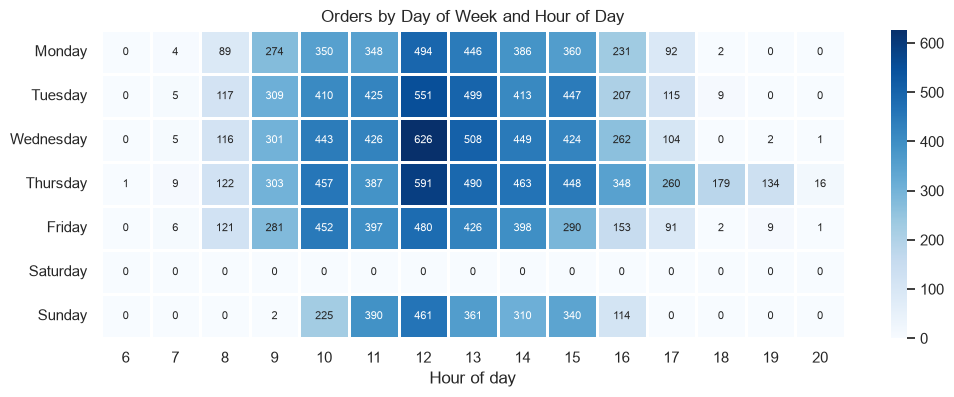

DayOfWeek
Monday       3076
Tuesday      3507
Wednesday    3667
Thursday     4208
Friday       3107
Saturday        0
Sunday       2203
Name: count, dtype: int64


In [36]:
# Orders by day and hour
orders = df.drop_duplicates("InvoiceNo")
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
table = pd.crosstab(orders["DayOfWeek"], orders["Hour"]).reindex(days, fill_value=0)

plt.figure(figsize=(12, 4))
sns.heatmap(table, cmap="Blues", annot=True, fmt="d", annot_kws={"size": 8}, linewidths=1)
plt.title("Orders by Day of Week and Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.show()

print(orders["DayOfWeek"].value_counts().reindex(days, fill_value=0))

- There are no orders on Saturday. The store was probably closed on Saturdays. Sunday is the quietest open day.
- Most orders come between 10:00 and 15:00, with the most at 12:00. This fits business customers ordering during work hours.
- Thursday is the busiest day, and it is the only day with many evening orders.

### 4.4 Sales by country

Number of countries: 38
UK share of revenue: 84.7%


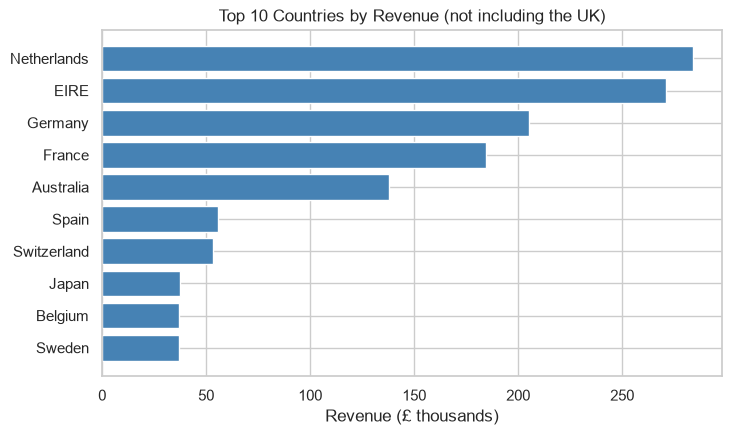

,revenue,customers,orders,percent
Country,,,,
United Kingdom,"8,402,375.19",3915,17896,84.66
Netherlands,"283,889.34",9,93,2.86
EIRE,"270,850.86",3,282,2.73
Germany,"205,381.15",94,443,2.07
France,"184,493.00",87,382,1.86
Australia,"138,103.81",9,56,1.39
Spain,"55,706.56",30,88,0.56
Switzerland,"53,065.60",21,50,0.53
Japan,"37,416.37",8,19,0.38


In [37]:
# Revenue by country
country = df.groupby("Country").agg(revenue=("LineTotal", "sum"),
                                     customers=("CustomerID", "nunique"),
                                     orders=("InvoiceNo", "nunique"))
country["percent"] = country["revenue"] / country["revenue"].sum() * 100
country = country.sort_values("revenue", ascending=False)
print("Number of countries:", len(country))
print(f"UK share of revenue: {country.loc['United Kingdom', 'percent']:.1f}%")

top10 = country.drop("United Kingdom").head(10)
plt.figure(figsize=(8, 4.5))
plt.barh(top10.index, top10["revenue"] / 1000, color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 Countries by Revenue (not including the UK)")
plt.xlabel("Revenue (£ thousands)")
plt.show()

country.head(11)

- The UK makes 84.7% of all revenue. Because of this, a simple "UK or not UK" column may be more useful than 38 different countries.
- After the UK, the biggest countries are the Netherlands, Ireland (EIRE), Germany and France.
- The Netherlands has only 9 customers and Ireland only 3, but they are still in the top 3. A few very big customers make most of their sales.

### 4.5 Best-selling products

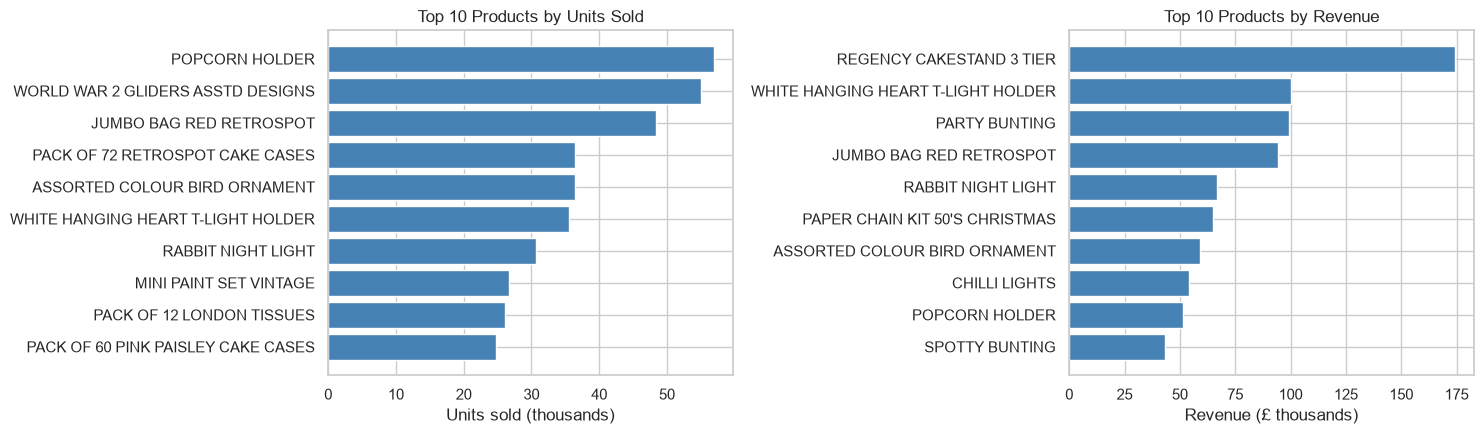

Number of products: 3798
Top 20% of products make 77.7% of revenue


In [38]:
# Top products
top_units = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
top_revenue = df.groupby("Description")["LineTotal"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(top_units.index, top_units.values / 1000, color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Top 10 Products by Units Sold")
axes[0].set_xlabel("Units sold (thousands)")
axes[1].barh(top_revenue.index, top_revenue.values / 1000, color="steelblue")
axes[1].invert_yaxis()
axes[1].set_title("Top 10 Products by Revenue")
axes[1].set_xlabel("Revenue (£ thousands)")
plt.tight_layout()
plt.show()

# Top 20% share
product_revenue = df.groupby("StockCode")["LineTotal"].sum().sort_values(ascending=False)
top_20_percent = product_revenue.head(int(len(product_revenue) * 0.2))
print("Number of products:", len(product_revenue))
print(f"Top 20% of products make {top_20_percent.sum() / product_revenue.sum() * 100:.1f}% of revenue")

- The two top 10 lists are different. Cheap items (popcorn holders, paper gliders) sell the most units, but the Regency Cakestand makes the most money (about £174k) because it costs more.
- The top 20% of products make 77.7% of revenue. This is close to the 80/20 rule.
- Many top products are for parties and home decor (bunting, cake cases, T-light holders). These might be bought together, which I can test with association rules.

### 4.6 Basket size

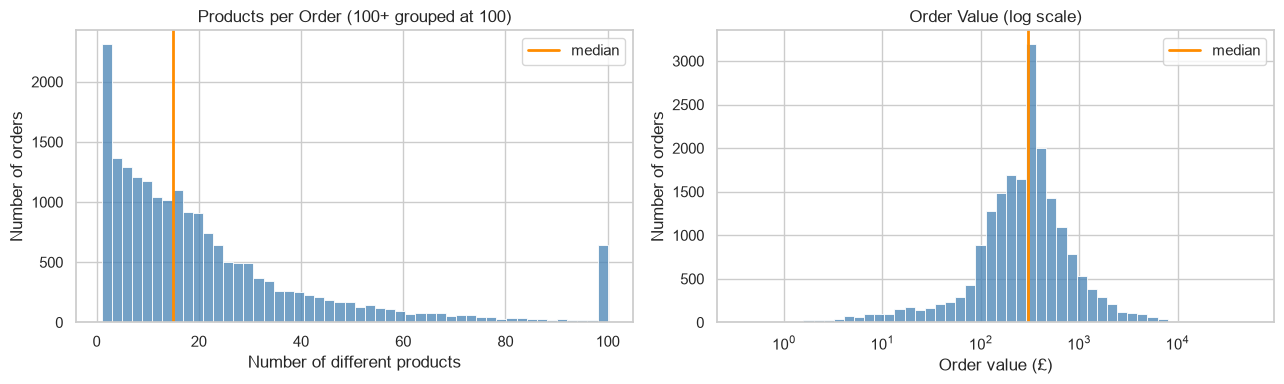

Number of orders: 19768
Orders with only 1 product: 1499


,products,value
count,"19,768.00","19,768.00"
mean,26.17,502.08
std,47.02,"1,133.76"
min,1.00,0.38
25%,6.00,151.66
50%,15.00,302.17
75%,29.00,481.00
max,"1,106.00","52,940.94"


In [39]:
# Basket size
basket = df.groupby("InvoiceNo").agg(products=("StockCode", "nunique"), value=("LineTotal", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(basket["products"].clip(upper=100), bins=50, ax=axes[0], color="steelblue")
axes[0].axvline(basket["products"].median(), color="darkorange", linewidth=2, label="median")
axes[0].set_title("Products per Order (100+ grouped at 100)")
axes[0].set_xlabel("Number of different products")
axes[0].set_ylabel("Number of orders")
axes[0].legend()
sns.histplot(basket["value"], bins=50, log_scale=True, ax=axes[1], color="steelblue")
axes[1].axvline(basket["value"].median(), color="darkorange", linewidth=2, label="median")
axes[1].set_title("Order Value (log scale)")
axes[1].set_xlabel("Order value (£)")
axes[1].set_ylabel("Number of orders")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Number of orders:", len(basket))
print("Orders with only 1 product:", (basket["products"] == 1).sum())
basket.describe()

- A typical order has 15 different products and is worth about £302. Only 7.6% of orders have just one product.
- This is good for association rules, because most baskets have many products.
- A few orders have more than 1,000 products. These could create a lot of weak rules, so in Deliverable 3 I may need to leave out very large baskets or use a higher minimum support.

### 4.7 Customer features (RFM)

For regression, classification and clustering I need one row per customer. I use RFM, which is a common way to describe customers:
- Recency: days since the last order
- Frequency: number of orders
- Monetary: total money spent

I also add the number of different products, how long the customer has been buying (TenureDays), average order value, and cancel rate.

In [40]:
# Customer table
known = df[df["HasCustomerID"]]

customers = known.groupby("CustomerID").agg(
    LastOrder=("InvoiceDate", "max"),
    FirstOrder=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    Products=("StockCode", "nunique"),
    Lines=("InvoiceNo", "size"),
    Country=("Country", "first"),
)

# Recency
end_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
customers["Recency"] = (end_date - customers["LastOrder"]).dt.days
customers["TenureDays"] = (end_date - customers["FirstOrder"]).dt.days
customers["AvgOrderValue"] = customers["Monetary"] / customers["Frequency"]

# Cancel rate
cancel_count = cancellations.groupby("CustomerID").size()
customers["Cancels"] = cancel_count.reindex(customers.index).fillna(0)
customers["CancelRate"] = customers["Cancels"] / (customers["Lines"] + customers["Cancels"])

customers = customers.drop(columns=["LastOrder", "FirstOrder", "Lines", "Cancels"])
print("Number of customers:", len(customers))
customers.describe()

Number of customers: 4333


,Frequency,Monetary,Products,Recency,TenureDays,AvgOrderValue,CancelRate
count,"4,333.00","4,333.00","4,333.00","4,333.00","4,333.00","4,333.00","4,333.00"
mean,4.25,"1,942.11",61.44,92.22,222.81,374.67,0.02
std,7.63,"8,383.09",85.31,100.13,117.84,454.61,0.06
min,1.00,2.90,1.00,0.00,0.00,2.90,0.00
25%,1.00,303.97,16.00,17.00,112.00,177.12,0.00
50%,2.00,661.32,35.00,50.00,248.00,289.45,0.00
75%,5.00,"1,625.97",77.00,142.00,326.00,423.21,0.02
max,206.00,"279,138.02","1,785.00",373.00,373.00,"12,425.45",0.83


There are 4,333 customers. A typical (median) customer spent £661 in 2 orders, and their last order was 50 days before the end of the data. For every money feature, the mean is much higher than the median, because a few big customers pull the mean up.

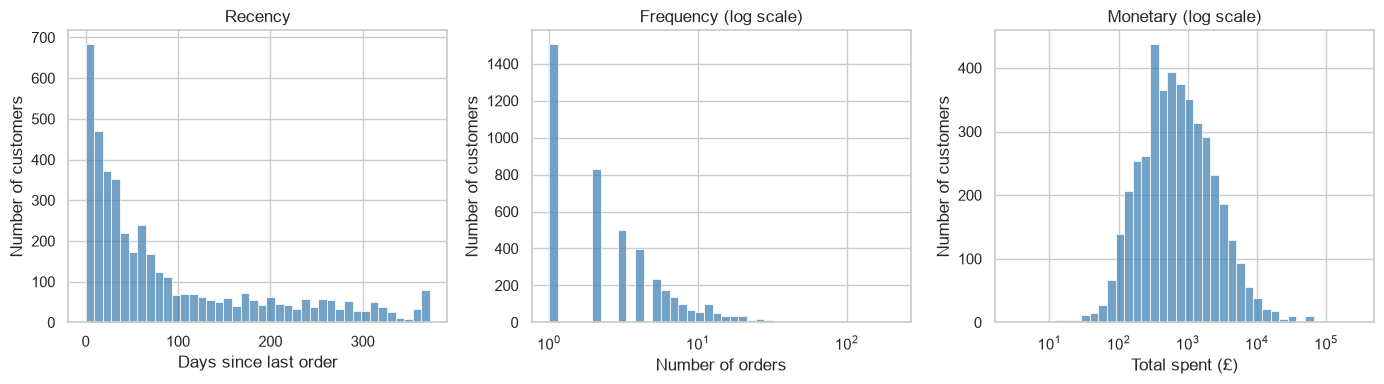

Customers with only 1 order: 1505 (34.7%)
Top 10% of customers make 60.0% of revenue


In [41]:
# RFM histograms
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(customers["Recency"], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Recency")
axes[0].set_xlabel("Days since last order")
sns.histplot(customers["Frequency"], bins=40, log_scale=True, ax=axes[1], color="steelblue")
axes[1].set_title("Frequency (log scale)")
axes[1].set_xlabel("Number of orders")
sns.histplot(customers["Monetary"], bins=40, log_scale=True, ax=axes[2], color="steelblue")
axes[2].set_title("Monetary (log scale)")
axes[2].set_xlabel("Total spent (£)")
for ax in axes:
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

one_order = (customers["Frequency"] == 1).mean() * 100
print(f"Customers with only 1 order: {(customers['Frequency'] == 1).sum()} ({one_order:.1f}%)")

top_10_percent = customers["Monetary"].sort_values(ascending=False).head(int(len(customers) * 0.1))
print(f"Top 10% of customers make {top_10_percent.sum() / customers['Monetary'].sum() * 100:.1f}% of revenue")

- Recency: Most customers ordered recently, but some have not ordered in 6–12 months. They might be lost customers.
- Frequency: 34.7% of customers ordered only once. Whether a customer orders again could be a classification target.
- Monetary: On a log scale, spending looks close to a bell shape. The top 10% of customers make 60.0% of revenue.

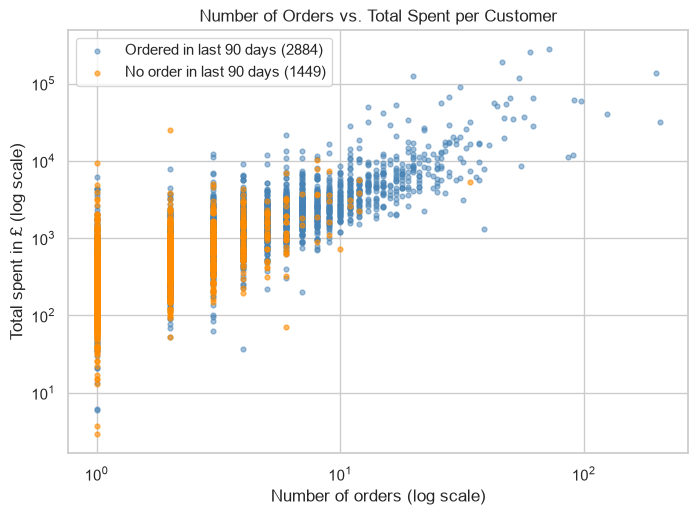

Correlation of log(Frequency) and log(Monetary): 0.81


In [42]:
# Orders vs. spending
recent = customers[customers["Recency"] <= 90]
not_recent = customers[customers["Recency"] > 90]

plt.figure(figsize=(8, 5.5))
plt.scatter(recent["Frequency"], recent["Monetary"], s=12, alpha=0.5, color="steelblue",
            label=f"Ordered in last 90 days ({len(recent)})")
plt.scatter(not_recent["Frequency"], not_recent["Monetary"], s=12, alpha=0.6, color="darkorange",
            label=f"No order in last 90 days ({len(not_recent)})")
plt.xscale("log")
plt.yscale("log")
plt.title("Number of Orders vs. Total Spent per Customer")
plt.xlabel("Number of orders (log scale)")
plt.ylabel("Total spent in £ (log scale)")
plt.legend()
plt.show()

print("Correlation of log(Frequency) and log(Monetary):",
      round(np.log(customers["Frequency"]).corr(np.log(customers["Monetary"])), 2))

Customers who order more also spend more (correlation 0.81 on the log scale). The customers with no order in the last 90 days (orange) are mostly customers with few orders and low spending. This suggests groups like "frequent big spenders", "new customers" and "one-time buyers who left". Clustering should be able to find them.

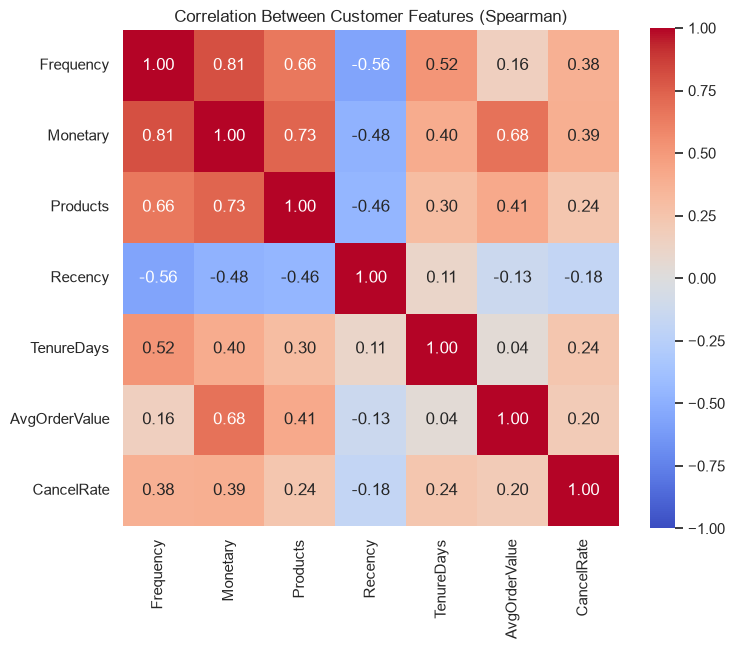

In [43]:
# Correlation
corr = customers.drop(columns=["Country"]).corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Between Customer Features (Spearman)")
plt.show()

- Frequency, Monetary and Products are strongly related (0.66 to 0.81). They all measure "how much a customer buys." In regression this can cause multicollinearity, so I may use only one or two of them, or use Ridge/Lasso.
- Recency is negatively related to these (around -0.5). Customers who ordered recently tend to buy more.
- CancelRate is positively related to Frequency (0.38). Customers who order more have more chances to cancel something, so a high cancel rate does not always mean an unhappy customer.

### 4.8 Cancellations

Cancelled lines: 8648
Cancelled value: £194,712 (2.0% of sales)
Customers who cancelled at least once: 1502 of 4333


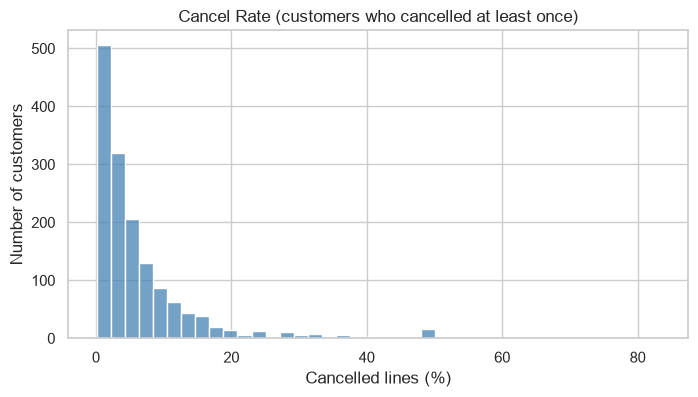

In [44]:
# Cancellation totals
cancel_value = -(cancellations["Quantity"] * cancellations["UnitPrice"]).sum()
print("Cancelled lines:", len(cancellations))
print(f"Cancelled value: £{cancel_value:,.0f} ({cancel_value / df['LineTotal'].sum() * 100:.1f}% of sales)")
print("Customers who cancelled at least once:", (customers["CancelRate"] > 0).sum(), "of", len(customers))

plt.figure(figsize=(8, 4))
sns.histplot(customers[customers["CancelRate"] > 0]["CancelRate"] * 100, bins=40, color="steelblue")
plt.title("Cancel Rate (customers who cancelled at least once)")
plt.xlabel("Cancelled lines (%)")
plt.ylabel("Number of customers")
plt.show()

Cancellations are about 2% of sales. About one third of customers (1,502 of 4,333) cancelled at least once. Most of them cancel only a small part of their order lines, but a few cancel more than half.

### Save the clean data

I save the clean sales, the cancellations and the customer table, so the next deliverables can start from the same clean data.

In [41]:
# Save clean data
df.drop(columns=["Month"]).to_csv("data/online_retail_clean.csv.gz", index=False)
cancellations.to_csv("data/cancellations.csv.gz", index=False)
customers.to_csv("data/customers.csv.gz")
print("Saved:", df.shape, cancellations.shape, customers.shape)

Saved: (522516, 13) (8648, 9) (4333, 8)


## Step 5: Insights and Next Steps

### What I learned

1. The data needed a lot of cleaning. Duplicates, cancellations, fees, staff notes and reversed orders were mixed in with the sales. After cleaning, I still kept 96.4% of the rows.
2. 25% of rows have no CustomerID. They look like guest orders. I can use them for product and basket analysis, but not for customer analysis.
3. Sales are seasonal. Sales almost double from September to November because of Christmas. December 2011 is not a full month.
4. No orders on Saturdays, and most orders come during work hours. This fits business customers.
5. A small part makes most of the money. The UK makes 84.7% of revenue, the top 20% of products make 77.7%, and the top 10% of customers make 60.0%.
6. The number columns are very skewed. On a log scale they look much more normal.
7. Customer features are related. Frequency, Monetary and Products go together, and Recency goes the other way.

### How this helps the next deliverables

- The data is skewed, so I will use log transforms and scale the features before modeling.
- Sales are seasonal and December 2011 is not a full month, so I will split train and test data by time.
- 34.7% of customers ordered only once, so "will order again" could be a classification target. I will use F1 and ROC, not only accuracy.
- Baskets are big, so I will use Apriori or FP-Growth and maybe leave out the very large baskets.
- The UK is most of the data, so I will use a "UK or not UK" column instead of 38 countries.
- I will use all rows for product and basket analysis, but only known customers for customer models.